In [1]:
import os
import re
import time
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence

print("Thư viện đã được import thành công.")

Thư viện đã được import thành công.


In [2]:
SEED = 42

# Đường dẫn dữ liệu khi notebook nằm trong thư mục lab_05
DATA_PATH = os.path.join("..", "data", "IMDB Dataset.csv")

# Chạy thử trước để tiết kiệm thời gian
QUICK_RUN = True

QUICK_TRAIN_PER_CLASS = 1500
QUICK_VAL_PER_CLASS = 400
QUICK_TEST_PER_CLASS = 400

MAX_VOCAB_SIZE = 20_000
MAX_LEN = 100
EMBED_DIM = 64
HIDDEN_DIM = 64
BATCH_SIZE = 64

EPOCHS = 1 if QUICK_RUN else 5
LEARNING_RATE = 1e-3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Quick run:", QUICK_RUN)
print("Dataset path:", os.path.abspath(DATA_PATH))

Device: cpu
Quick run: True
Dataset path: d:\My_project\NLP_LABS\data\IMDB Dataset.csv


In [3]:
if not os.path.exists(DATA_PATH):
    fallback_path = r"D:\My_project\NLP_LABS\data\IMDB Dataset.csv"

    if os.path.exists(fallback_path):
        DATA_PATH = fallback_path
    else:
        raise FileNotFoundError(
            "Không tìm thấy IMDB Dataset.csv. "
            "Hãy kiểm tra lại DATA_PATH."
        )

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset shape: (50000, 2)
Columns: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
required_columns = {"review", "sentiment"}

if not required_columns.issubset(df.columns):
    raise ValueError(
        f"Dataset phải có các cột: {required_columns}"
    )

print("Missing values:")
print(df[["review", "sentiment"]].isnull().sum())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print(
    "\nDuplicate rows:",
    df.duplicated(subset=["review", "sentiment"]).sum()
)

Missing values:
review       0
sentiment    0
dtype: int64

Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Duplicate rows: 418


In [5]:
def clean_text(text):
    text = str(text)

    # Xóa HTML tags như <br />
    text = re.sub(r"<[^>]+>", " ", text)

    # Chuyển thành chữ thường
    text = text.lower()

    # Giữ chữ cái, chữ số, dấu nháy và khoảng trắng
    text = re.sub(r"[^a-z0-9'\s]", " ", text)

    # Gộp nhiều khoảng trắng thành một
    text = re.sub(r"\s+", " ", text).strip()

    return text


df = df.dropna(subset=["review", "sentiment"]).copy()

df["clean_review"] = df["review"].apply(clean_text)

df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

if df["label"].isnull().any():
    raise ValueError("Có nhãn không hợp lệ.")

display(
    df[["review", "clean_review", "sentiment", "label"]].head()
)

,review,clean_review,sentiment,label
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...,positive,1
1,A wonderful little production. <br /><br />The...,a wonderful little production the filming tech...,positive,1
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...,positive,1
3,Basically there's a family where a little boy ...,basically there's a family where a little boy ...,negative,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei's love in the time of money is a...,positive,1


Minimum length: 6
Median length: 173.0
Mean length: 231.03
Maximum length: 2473


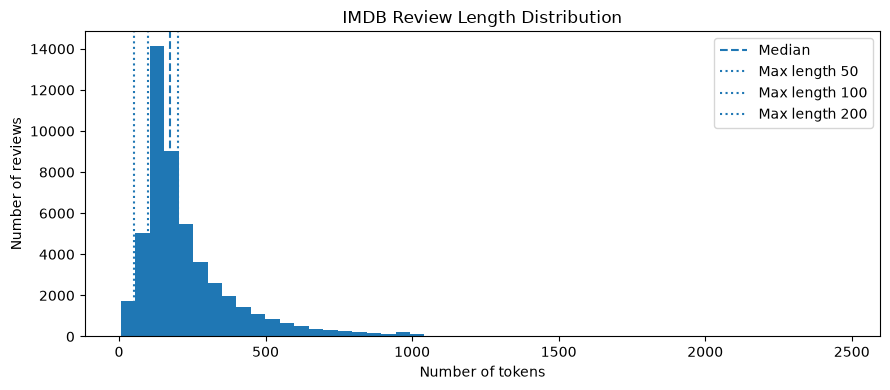

In [6]:
df["seq_len"] = df["clean_review"].apply(
    lambda text: len(text.split())
)

print("Minimum length:", df["seq_len"].min())
print("Median length:", df["seq_len"].median())
print("Mean length:", round(df["seq_len"].mean(), 2))
print("Maximum length:", df["seq_len"].max())

plt.figure(figsize=(9, 4))

plt.hist(df["seq_len"], bins=50)

plt.axvline(
    df["seq_len"].median(),
    linestyle="--",
    label="Median"
)

plt.axvline(50, linestyle=":", label="Max length 50")
plt.axvline(100, linestyle=":", label="Max length 100")
plt.axvline(200, linestyle=":", label="Max length 200")

plt.xlabel("Number of tokens")
plt.ylabel("Number of reviews")
plt.title("IMDB Review Length Distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTrain label distribution:")
print(train_df["sentiment"].value_counts())

Train: 40000
Validation: 5000
Test: 5000

Train label distribution:
sentiment
positive    20000
negative    20000
Name: count, dtype: int64


In [8]:
if QUICK_RUN:

    def balanced_subset(frame, per_class, seed):
        parts = []

        for label in sorted(frame["label"].unique()):
            part = frame[frame["label"] == label]

            n = min(per_class, len(part))

            parts.append(
                part.sample(n=n, random_state=seed)
            )

        return (
            pd.concat(parts)
            .sample(frac=1, random_state=seed)
            .reset_index(drop=True)
        )

    train_df = balanced_subset(
        train_df, QUICK_TRAIN_PER_CLASS, SEED
    )

    val_df = balanced_subset(
        val_df, QUICK_VAL_PER_CLASS, SEED
    )

    test_df = balanced_subset(
        test_df, QUICK_TEST_PER_CLASS, SEED
    )


print("Working train size:", len(train_df))
print("Working validation size:", len(val_df))
print("Working test size:", len(test_df))

Working train size: 3000
Working validation size: 800
Working test size: 800


Tokenizer và Vocabulary

In [9]:
def tokenize(text):
    return re.findall(
        r"[a-z0-9]+(?:'[a-z]+)?",
        str(text).lower()
    )


token_counts = Counter()

for review in train_df["clean_review"]:
    token_counts.update(tokenize(review))


print("Unique tokens:", len(token_counts))

print("\nMost common 20 tokens:")
print(token_counts.most_common(20))

Unique tokens: 32223

Most common 20 tokens:
[('the', 39656), ('a', 19153), ('and', 19128), ('of', 17044), ('to', 15637), ('is', 12487), ('in', 11116), ('it', 9246), ('i', 9110), ('this', 9001), ('that', 8065), ('was', 5669), ('as', 5377), ('with', 5204), ('movie', 5189), ('for', 5124), ('but', 4795), ('film', 4670), ('on', 3938), ('you', 3618)]


In [10]:
class Vocabulary:

    def __init__(self, max_size=20_000):
        self.max_size = max_size

        self.word_to_id = {
            "<PAD>": 0,
            "<UNK>": 1
        }

        self.id_to_word = {
            0: "<PAD>",
            1: "<UNK>"
        }

    def build(self, texts):
        counter = Counter()

        for text in texts:
            counter.update(tokenize(text))

        for word, _ in counter.most_common(
            self.max_size - 2
        ):
            if word not in self.word_to_id:
                idx = len(self.word_to_id)

                self.word_to_id[word] = idx
                self.id_to_word[idx] = word

    def encode(self, text, max_len=100):
        tokens = tokenize(text)

        original_length = len(tokens)

        # Truncation: cắt chuỗi nếu quá dài
        tokens = tokens[:max_len]

        # Chuyển từ thành ID
        ids = [
            self.word_to_id.get(
                token,
                self.word_to_id["<UNK>"]
            )
            for token in tokens
        ]

        # Độ dài thật trước khi padding
        length = max(1, len(ids))

        # Padding: thêm 0 nếu chuỗi quá ngắn
        if len(ids) < max_len:
            ids += [self.word_to_id["<PAD>"]] * (
                max_len - len(ids)
            )

        return ids, length, original_length


vocab = Vocabulary(max_size=MAX_VOCAB_SIZE)

vocab.build(train_df["clean_review"])

print("Vocabulary size:", len(vocab.word_to_id))
print("PAD ID:", vocab.word_to_id["<PAD>"])
print("UNK ID:", vocab.word_to_id["<UNK>"])

print("\nExample mappings:")

for word in ["the", "movie", "good", "excellent"]:
    print(
        f"{word}:",
        vocab.word_to_id.get(
            word,
            vocab.word_to_id["<UNK>"]
        )
    )

Vocabulary size: 20000
PAD ID: 0
UNK ID: 1

Example mappings:
the: 2
movie: 16
good: 48
excellent: 325


In [11]:
sample_review = "The movie was really excellent!"

sample_ids, sample_length, original_length = vocab.encode(
    sample_review,
    max_len=MAX_LEN
)

print("Original review:", sample_review)
print("Token IDs (first 20):", sample_ids[:20])
print("Actual sequence length:", sample_length)
print("Encoded length:", len(sample_ids))
print(
    "Padding tokens:",
    sample_ids.count(vocab.word_to_id["<PAD>"])
)

Original review: The movie was really excellent!
Token IDs (first 20): [2, 16, 13, 63, 325, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Actual sequence length: 5
Encoded length: 100
Padding tokens: 95


Dataset và mô hình

In [12]:
class IMDbDataset(Dataset):

    def __init__(self, frame, vocab, max_len=100):
        self.texts = frame["clean_review"].tolist()

        self.labels = (
            frame["label"]
            .astype("float32")
            .tolist()
        )

        self.vocab = vocab
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        ids, length, _ = self.vocab.encode(
            self.texts[idx],
            self.max_len
        )

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(length, dtype=torch.long),
            torch.tensor(
                self.labels[idx],
                dtype=torch.float32
            )
        )


train_dataset = IMDbDataset(
    train_df, vocab, MAX_LEN
)

val_dataset = IMDbDataset(
    val_df, vocab, MAX_LEN
)

test_dataset = IMDbDataset(
    test_df, vocab, MAX_LEN
)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


x_example, length_example, y_example = next(
    iter(train_loader)
)

print("Token batch shape:", x_example.shape)
print("Length batch shape:", length_example.shape)
print("Label batch shape:", y_example.shape)

Token batch shape: torch.Size([64, 100])
Length batch shape: torch.Size([64])
Label batch shape: torch.Size([64])


In [13]:
class SentimentModel(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim=64,
        hidden_dim=64,
        cell_type="LSTM"
    ):
        super().__init__()

        self.cell_type = cell_type

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=0
        )

        if cell_type == "RNN":
            self.recurrent = nn.RNN(
                embed_dim,
                hidden_dim,
                batch_first=True
            )

        elif cell_type == "LSTM":
            self.recurrent = nn.LSTM(
                embed_dim,
                hidden_dim,
                batch_first=True
            )

        elif cell_type == "GRU":
            self.recurrent = nn.GRU(
                embed_dim,
                hidden_dim,
                batch_first=True
            )

        else:
            raise ValueError(
                "cell_type phải là RNN, LSTM hoặc GRU"
            )

        self.classifier = nn.Linear(
            hidden_dim,
            1
        )

    def forward(self, token_ids, lengths):
        embedded = self.embedding(token_ids)

        packed = torch.nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        if self.cell_type == "LSTM":
            _, (hidden, _) = self.recurrent(packed)
        else:
            _, hidden = self.recurrent(packed)

        last_hidden = hidden[-1]

        logits = self.classifier(last_hidden).squeeze(1)

        return logits


test_model = SentimentModel(
    vocab_size=len(vocab.word_to_id),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    cell_type="LSTM"
).to(device)


with torch.no_grad():
    sample_logits = test_model(
        x_example.to(device),
        length_example.to(device)
    )

print("Output shape:", sample_logits.shape)

Output shape: torch.Size([64])


In [14]:
def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None
):
    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.set_grad_enabled(training):

        for token_ids, lengths, labels in loader:

            token_ids = token_ids.to(device)
            lengths = lengths.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad()

            logits = model(token_ids, lengths)

            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item()

            preds = (
                torch.sigmoid(logits) >= 0.5
            ).long()

            all_preds.extend(
                preds.detach().cpu().numpy()
            )

            all_labels.extend(
                labels.detach().cpu().numpy()
            )

    avg_loss = total_loss / max(1, len(loader))

    accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    return avg_loss, accuracy, all_preds, all_labels


def train_model(
    model,
    train_loader,
    val_loader,
    epochs=1,
    lr=1e-3
):
    criterion = nn.BCEWithLogitsLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=lr
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    start_time = time.time()

    for epoch in range(epochs):

        train_loss, train_acc, _, _ = run_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        val_loss, val_acc, _, _ = run_epoch(
            model,
            val_loader,
            criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"train_acc={train_acc:.4f} | "
            f"val_acc={val_acc:.4f}"
        )

    elapsed = time.time() - start_time

    return history, elapsed

In [15]:
neural_results = []
trained_models = {}
histories = {}

for cell_type in ["RNN", "LSTM", "GRU"]:

    print(f"\n--- Training {cell_type} ---")

    model = SentimentModel(
        vocab_size=len(vocab.word_to_id),
        embed_dim=EMBED_DIM,
        hidden_dim=HIDDEN_DIM,
        cell_type=cell_type
    ).to(device)

    history, elapsed = train_model(
        model,
        train_loader,
        val_loader,
        epochs=EPOCHS,
        lr=LEARNING_RATE
    )

    criterion = nn.BCEWithLogitsLoss()

    test_loss, test_acc, test_preds, test_labels = run_epoch(
        model,
        test_loader,
        criterion
    )

    precision, recall, f1, _ = precision_recall_fscore_support(
        test_labels,
        test_preds,
        average="binary",
        zero_division=0
    )

    trained_models[cell_type] = model
    histories[cell_type] = history

    neural_results.append({
        "Model": cell_type,
        "Test Loss": test_loss,
        "Accuracy": test_acc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Training Time (sec)": elapsed
    })


results_df = pd.DataFrame(neural_results)

display(results_df)


--- Training RNN ---
Epoch 1/1 | train_loss=0.7027 | val_loss=0.6949 | train_acc=0.4897 | val_acc=0.5275

--- Training LSTM ---
Epoch 1/1 | train_loss=0.6931 | val_loss=0.6947 | train_acc=0.5157 | val_acc=0.5100

--- Training GRU ---
Epoch 1/1 | train_loss=0.6963 | val_loss=0.6923 | train_acc=0.5023 | val_acc=0.5225


,Model,Test Loss,Accuracy,Precision,Recall,F1,Training Time (sec)
0,RNN,0.692389,0.53125,0.528868,0.5725,0.549820,1.524345
1,LSTM,0.694675,0.50500,0.505952,0.4250,0.461957,3.591567
2,GRU,0.695860,0.50500,0.505464,0.4625,0.483029,2.885021


In [16]:
baseline_start = time.time()

tfidf = TfidfVectorizer(
    max_features=MAX_VOCAB_SIZE
)

X_train_tfidf = tfidf.fit_transform(
    train_df["clean_review"]
)

X_test_tfidf = tfidf.transform(
    test_df["clean_review"]
)

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

lr_model.fit(
    X_train_tfidf,
    train_df["label"]
)

lr_time = time.time() - baseline_start

lr_preds = lr_model.predict(X_test_tfidf)

lr_precision, lr_recall, lr_f1, _ = precision_recall_fscore_support(
    test_df["label"],
    lr_preds,
    average="binary",
    zero_division=0
)

baseline_result = {
    "Model": "TF-IDF + Logistic Regression",
    "Accuracy": accuracy_score(
        test_df["label"], lr_preds
    ),
    "Precision": lr_precision,
    "Recall": lr_recall,
    "F1": lr_f1,
    "Training Time (sec)": lr_time
}

print(
    classification_report(
        test_df["label"],
        lr_preds,
        target_names=["negative", "positive"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    negative       0.86      0.84      0.85       400
    positive       0.84      0.86      0.85       400

    accuracy                           0.85       800
   macro avg       0.85      0.85      0.85       800
weighted avg       0.85      0.85      0.85       800



In [17]:
baseline_df = pd.DataFrame([baseline_result])

all_results_df = pd.concat(
    [
        baseline_df,
        results_df
    ],
    ignore_index=True,
    sort=False
)

display(
    all_results_df.sort_values(
        "Accuracy",
        ascending=False
    )
)

all_results_df.to_csv(
    "results.csv",
    index=False
)

print("Saved results.csv")

,Model,Accuracy,Precision,Recall,F1,Training Time (sec),Test Loss
0,TF-IDF + Logistic Regression,0.85000,0.844828,0.8575,0.851117,0.559591,NaN
1,RNN,0.53125,0.528868,0.5725,0.549820,1.524345,0.692389
2,LSTM,0.50500,0.505952,0.4250,0.461957,3.591567,0.694675
3,GRU,0.50500,0.505464,0.4625,0.483029,2.885021,0.695860


Saved results.csv


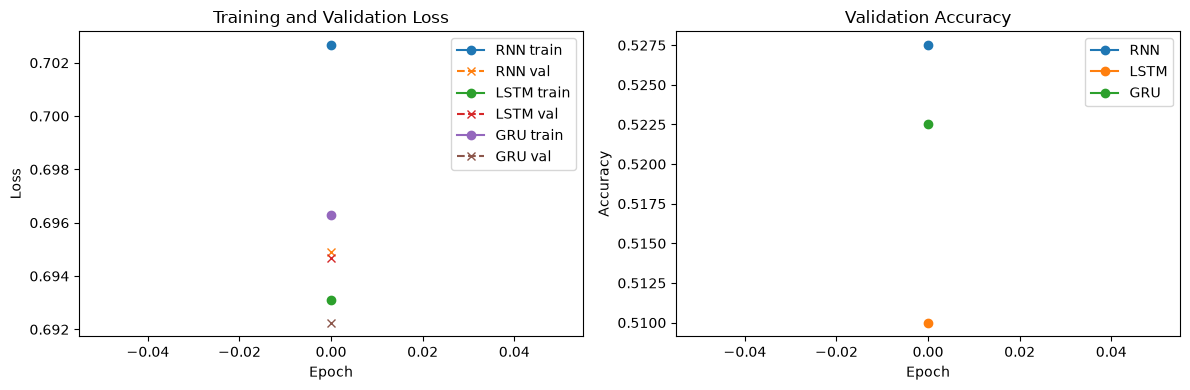

In [18]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4)
)

for name, history in histories.items():

    axes[0].plot(
        history["train_loss"],
        marker="o",
        label=f"{name} train"
    )

    axes[0].plot(
        history["val_loss"],
        marker="x",
        linestyle="--",
        label=f"{name} val"
    )

    axes[1].plot(
        history["val_acc"],
        marker="o",
        label=name
    )

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()

plt.savefig(
    "learning_curves.png",
    dpi=150
)

plt.show()

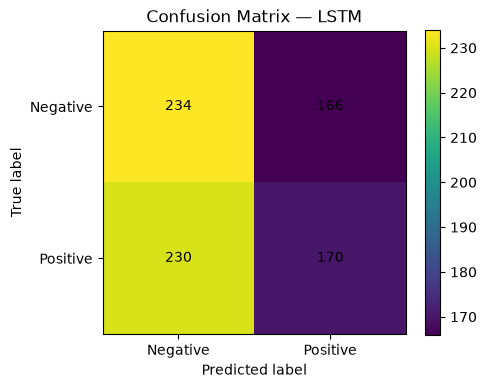

In [19]:
lstm_model = trained_models["LSTM"]

_, _, lstm_preds, lstm_labels = run_epoch(
    lstm_model,
    test_loader,
    nn.BCEWithLogitsLoss()
)

cm = confusion_matrix(
    lstm_labels,
    lstm_preds,
    labels=[0, 1]
)

plt.figure(figsize=(5, 4))

plt.imshow(cm)

plt.title("Confusion Matrix — LSTM")
plt.xlabel("Predicted label")
plt.ylabel("True label")

plt.xticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.yticks(
    [0, 1],
    ["Negative", "Positive"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j, i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=150
)

plt.show()

In [20]:
test_texts = test_df["clean_review"].tolist()

test_true = (
    test_df["label"]
    .astype(int)
    .tolist()
)

test_pred = [
    int(x)
    for x in lstm_preds
]

wrong_indices = [
    i
    for i, (true_label, pred_label)
    in enumerate(zip(test_true, test_pred))
    if true_label != pred_label
]

print(
    "Number of incorrect predictions:",
    len(wrong_indices)
)

for i in wrong_indices[:5]:

    print("-" * 80)

    print(
        "Review:",
        test_texts[i][:600]
    )

    print(
        "True label:",
        "positive" if test_true[i] == 1 else "negative"
    )

    print(
        "Predicted:",
        "positive" if test_pred[i] == 1 else "negative"
    )

Number of incorrect predictions: 396
--------------------------------------------------------------------------------
Review: i will never go to another tarantino movie again the entire film was worthless my wife and i both regret that we didn't get up and walk out at the first indication of what the film was really going to be about which is still hard to determine since it was such a ridiculous storyline blood guts and violence seemed to be the only real theme but we kept hoping there'd be something redeeming just around the corner unfortunately there wasn't because there wasn't anything that made sense we along with a lot of the other people in the audience walked out of the theater muttering that was disgusting w
True label: negative
Predicted: positive
--------------------------------------------------------------------------------
Review: i used to like some of the hollywood action blockbusters of the 80s they had icons such as arnie and sly but i think the action movie in the '9

In [21]:
def predict_sentiment(
    text,
    model,
    vocab,
    max_len=MAX_LEN
):
    model.eval()

    cleaned = clean_text(text)

    ids, length, _ = vocab.encode(
        cleaned,
        max_len=max_len
    )

    token_tensor = torch.tensor(
        [ids],
        dtype=torch.long
    ).to(device)

    length_tensor = torch.tensor(
        [length],
        dtype=torch.long
    ).to(device)

    with torch.no_grad():

        logit = model(
            token_tensor,
            length_tensor
        )

        probability = torch.sigmoid(logit).item()

    sentiment = (
        "positive"
        if probability >= 0.5
        else "negative"
    )

    return sentiment, probability


demo_reviews = [
    "I really enjoyed this movie. The acting was excellent.",
    "The plot was boring and the acting was terrible.",
    "I thought it would be bad, but it was surprisingly good."
]

for review in demo_reviews:

    prediction, probability = predict_sentiment(
        review,
        trained_models["LSTM"],
        vocab
    )

    print("Review:", review)

    print(
        f"Prediction: {prediction} "
        f"(positive probability={probability:.3f})"
    )

    print()

Review: I really enjoyed this movie. The acting was excellent.
Prediction: positive (positive probability=0.505)

Review: The plot was boring and the acting was terrible.
Prediction: positive (positive probability=0.510)

Review: I thought it would be bad, but it was surprisingly good.
Prediction: negative (positive probability=0.497)



In [22]:
RUN_SEQUENCE_LENGTH_EXPERIMENT = False

if RUN_SEQUENCE_LENGTH_EXPERIMENT:

    sequence_results = []

    for max_len in [50, 100, 200]:

        print(
            f"\n--- LSTM with max_len={max_len} ---"
        )

        train_ds = IMDbDataset(
            train_df, vocab, max_len
        )

        val_ds = IMDbDataset(
            val_df, vocab, max_len
        )

        test_ds = IMDbDataset(
            test_df, vocab, max_len
        )

        train_dl = DataLoader(
            train_ds,
            batch_size=BATCH_SIZE,
            shuffle=True
        )

        val_dl = DataLoader(
            val_ds,
            batch_size=BATCH_SIZE,
            shuffle=False
        )

        test_dl = DataLoader(
            test_ds,
            batch_size=BATCH_SIZE,
            shuffle=False
        )

        model = SentimentModel(
            len(vocab.word_to_id),
            EMBED_DIM,
            HIDDEN_DIM,
            cell_type="LSTM"
        ).to(device)

        history, elapsed = train_model(
            model,
            train_dl,
            val_dl,
            epochs=EPOCHS,
            lr=LEARNING_RATE
        )

        _, accuracy, preds, labels = run_epoch(
            model,
            test_dl,
            nn.BCEWithLogitsLoss()
        )

        _, _, f1, _ = precision_recall_fscore_support(
            labels,
            preds,
            average="binary",
            zero_division=0
        )

        avg_retained = np.mean([
            min(
                1.0,
                max_len / max(1, length)
            )
            for length in train_df["seq_len"]
        ]) * 100

        sequence_results.append({
            "Max Length": max_len,
            "Average tokens retained (%)": avg_retained,
            "Accuracy": accuracy,
            "F1": f1,
            "Training Time (sec)": elapsed
        })

    sequence_results_df = pd.DataFrame(
        sequence_results
    )

    display(sequence_results_df)

else:
    print(
        "Skipped. Set RUN_SEQUENCE_LENGTH_EXPERIMENT = True "
        "to run this experiment."
    )

Skipped. Set RUN_SEQUENCE_LENGTH_EXPERIMENT = True to run this experiment.


In [23]:
print(
    "Current working directory:",
    os.getcwd()
)

for filename in [
    "results.csv",
    "learning_curves.png",
    "confusion_matrix.png"
]:

    status = (
        "found"
        if os.path.exists(filename)
        else "not created yet"
    )

    print(f"{filename}: {status}")

Current working directory: d:\My_project\NLP_LABS\lab_05
results.csv: found
learning_curves.png: found
confusion_matrix.png: found
